In [8]:
import os
import cv2
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt

In [9]:
DATASET_ROOT = Path(
    "/workspace/202427000031/DEP-RNet/data/raw/visdrone"
)

SPLITS = {
    "train": DATASET_ROOT / "VisDrone2019-DET-train" / "VisDrone2019-DET-train",
    "val": DATASET_ROOT / "VisDrone2019-DET-val" / "VisDrone2019-DET-val",
    "test-dev": DATASET_ROOT / "VisDrone2019-DET-test-challenge" / "VisDrone2019-DET-test-challenge"
}
print(DATASET_ROOT)

/workspace/202427000031/DEP-RNet/data/raw/visdrone


In [10]:
CLASS_NAMES = {
    1: "pedestrian",
    2: "people",
    3: "bicycle",
    4: "car",
    5: "van",
    6: "truck",
    7: "tricycle",
    8: "awning-tricycle",
    9: "bus",
    10: "motor"
}

CLASS_NAMES

{1: 'pedestrian',
 2: 'people',
 3: 'bicycle',
 4: 'car',
 5: 'van',
 6: 'truck',
 7: 'tricycle',
 8: 'awning-tricycle',
 9: 'bus',
 10: 'motor'}

In [11]:
#Lecture des annotations

In [12]:
def parse_annotation(
    annotation_path,
    image_path,
    split_name
):
    """
    Read a VisDrone annotation file.

    Original format:
    bbox_left, bbox_top, bbox_width, bbox_height,
    score, object_category, truncation, occlusion
    """

    rows = []

    with open(annotation_path, "r") as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            values = line.split(",")

            if len(values) < 8:
                continue

            x = int(values[0])
            y = int(values[1])
            w = int(values[2])
            h = int(values[3])

            score = int(values[4])
            category = int(values[5])
            truncation = int(values[6])
            occlusion = int(values[7])

            # Ignore regions = category 0
            # "others" = category 11
            if category == 0 or category == 11:
                continue

            rows.append({
                "split": split_name,
                "image": image_path.name,
                "image_path": str(image_path),
                "annotation_path": str(annotation_path),

                "x": x,
                "y": y,
                "width": w,
                "height": h,

                "category_id": category,
                "category": CLASS_NAMES.get(
                    category,
                    "unknown"
                ),

                "truncation": truncation,
                "occlusion": occlusion
            })

    return rows

In [13]:
#Analyse complete du dataset

In [14]:
all_annotations = []
image_records = []

for split_name, split_path in SPLITS.items():

    image_dir = split_path / "images"
    annotation_dir = split_path / "annotations"

    image_files = list(
        image_dir.glob("*.jpg")
    )

    print(
        f"{split_name}: "
        f"{len(image_files)} images"
    )

    for image_path in image_files:

        image_records.append({
            "split": split_name,
            "image": image_path.name,
            "image_path": str(image_path)
        })

        annotation_path = (
            annotation_dir /
            f"{image_path.stem}.txt"
        )

        if annotation_path.exists():

            rows = parse_annotation(
                annotation_path,
                image_path,
                split_name
            )

            all_annotations.extend(rows)

train: 6471 images
val: 548 images
test-dev: 1580 images


In [15]:
#DataFrame

In [16]:
df = pd.DataFrame(
    all_annotations
)

images_df = pd.DataFrame(
    image_records
)

print(
    "Images:",
    len(images_df)
)

print(
    "Objects:",
    len(df)
)

df.head()

Images: 8599
Objects: 381964


,split,image,image_path,annotation_path,x,y,width,height,category_id,category,truncation,occlusion
0,train,9999999_00837_d_0000382.jpg,/workspace/202427000031/DEP-RNet/data/raw/visd...,/workspace/202427000031/DEP-RNet/data/raw/visd...,1838,1322,117,166,4,car,0,0
1,train,9999999_00837_d_0000382.jpg,/workspace/202427000031/DEP-RNet/data/raw/visd...,/workspace/202427000031/DEP-RNet/data/raw/visd...,1609,1087,76,112,4,car,0,0
2,train,9999999_00837_d_0000382.jpg,/workspace/202427000031/DEP-RNet/data/raw/visd...,/workspace/202427000031/DEP-RNet/data/raw/visd...,1351,1176,129,124,4,car,0,1
3,train,9999999_00837_d_0000382.jpg,/workspace/202427000031/DEP-RNet/data/raw/visd...,/workspace/202427000031/DEP-RNet/data/raw/visd...,1325,948,92,80,4,car,0,0
4,train,9999999_00837_d_0000382.jpg,/workspace/202427000031/DEP-RNet/data/raw/visd...,/workspace/202427000031/DEP-RNet/data/raw/visd...,1149,975,85,74,4,car,0,0


In [ ]:
#Résumé_général

In [17]:
summary = []

for split in SPLITS.keys():

    n_images = (
        images_df["split"]
        .eq(split)
        .sum()
    )

    n_objects = (
        df["split"]
        .eq(split)
        .sum()
    )

    avg_objects = (
        n_objects / n_images
        if n_images > 0
        else 0
    )

    summary.append({
        "split": split,
        "images": n_images,
        "objects": n_objects,
        "objects_per_image":
            avg_objects
    })

summary_df = pd.DataFrame(
    summary
)

summary_df

,split,images,objects,objects_per_image
0,train,6471,343205,53.037398
1,val,548,38759,70.728102
2,test-dev,1580,0,0.000000


In [18]:
#Nombre d'images par split

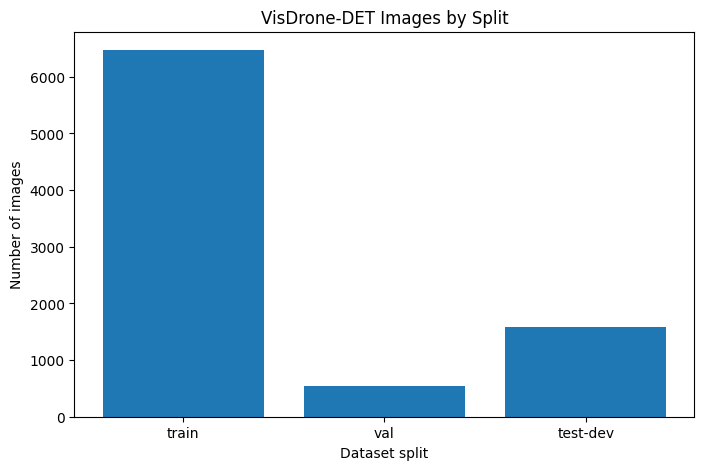

In [22]:
plt.figure(figsize=(8, 5))

plt.bar(
    summary_df["split"],
    summary_df["images"]
)

plt.title(
    "VisDrone-DET Images by Split"
)

plt.xlabel(
    "Dataset split"
)

plt.ylabel(
    "Number of images"
)

plt.show()

In [23]:
#Distribution des classes

In [24]:
class_counts = (
    df["category"]
    .value_counts()
)

class_counts

category
car                158931
pedestrian          88181
motor               34533
people              32184
van                 26931
truck               13625
bicycle             11767
bus                  6177
tricycle             5857
awning-tricycle      3778
Name: count, dtype: int64

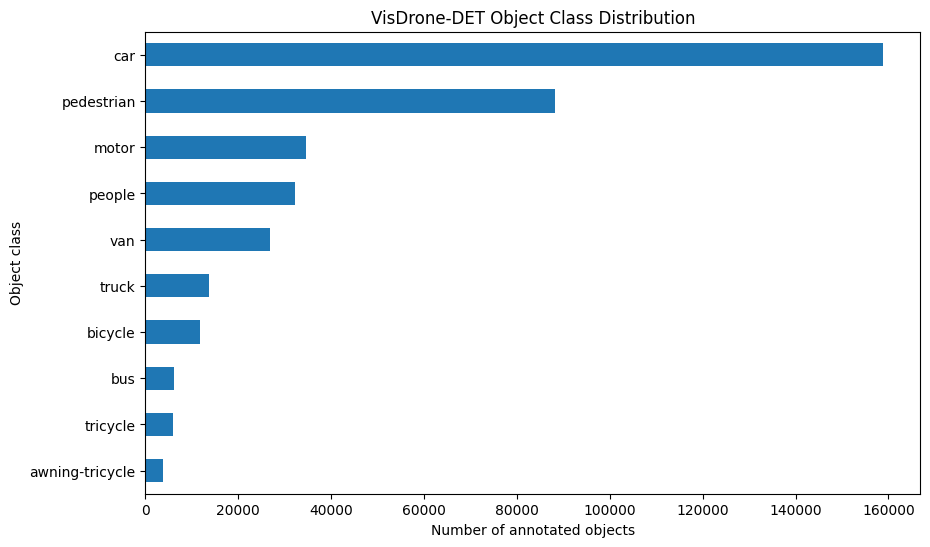

In [28]:
plt.figure(figsize=(10, 6))

class_counts.sort_values().plot(
    kind="barh"
)

plt.title(
    "VisDrone-DET Object Class Distribution"
)

plt.xlabel(
    "Number of annotated objects"
)

plt.ylabel(
    "Object class"
)

plt.show()

In [27]:
#Nombre d'objet par images

In [30]:
objects_per_image = (
    df.groupby(
        ["split", "image"]
    )
    .size()
    .reset_index(
        name="object_count"
    )
)

objects_per_image.head()

,split,image,object_count
0,train,0000002_00005_d_0000014.jpg,82
1,train,0000002_00448_d_0000015.jpg,85
2,train,0000003_00231_d_0000016.jpg,39
3,train,0000007_04999_d_0000036.jpg,57
4,train,0000007_05499_d_0000037.jpg,60


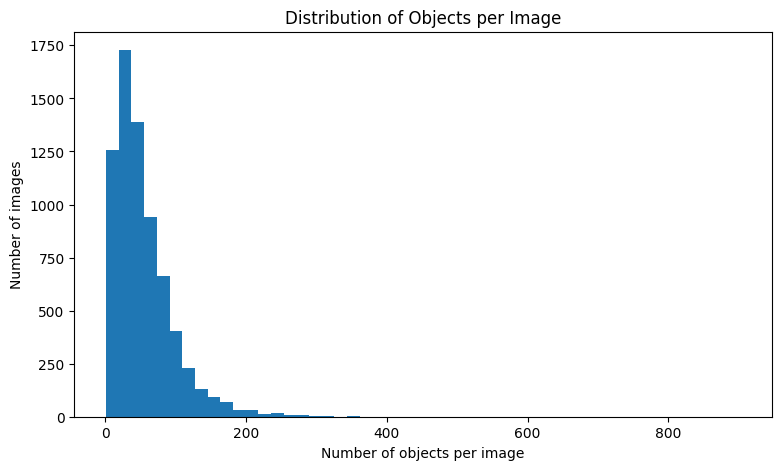

In [31]:
#Distribution de la densité des objets
plt.figure(figsize=(9, 5))

plt.hist(
    objects_per_image["object_count"],
    bins=50
)

plt.title(
    "Distribution of Objects per Image"
)

plt.xlabel(
    "Number of objects per image"
)

plt.ylabel(
    "Number of images"
)

plt.show()

In [32]:
objects_per_image[
    "object_count"
].describe()

count    7019.000000
mean       54.418578
std        44.265656
min         1.000000
25%        24.000000
50%        43.000000
75%        72.000000
max       902.000000
Name: object_count, dtype: float64

In [33]:
#Analyse de la taille des objets

In [35]:
df["area"] = (
    df["width"] *
    df["height"]
)

In [36]:
#Proposition de l'image occupé

In [40]:
def get_image_size(image_path):

    img = cv2.imread(
        image_path
    )

    if img is None:
        return None, None

    h, w = img.shape[:2]

    return w, h

In [42]:
widths = []
heights = []

for path in df["image_path"]:

    w, h = get_image_size(path)

    widths.append(w)
    heights.append(h)

df["image_width"] = widths
df["image_height"] = heights

In [43]:
#Surface relative de l'objet
df["relative_area"] = (

    df["width"] *
    df["height"]

) / (

    df["image_width"] *
    df["image_height"]

)

In [44]:
#Taille moyenne des objets

In [45]:
df["relative_area"] = (

    df["width"] *
    df["height"]

) / (

    df["image_width"] *
    df["image_height"]

)

In [46]:
#Classification des petit objets
def classify_object_size(
    relative_area
):

    if relative_area < 0.0005:
        return "very_small"

    elif relative_area < 0.002:
        return "small"

    elif relative_area < 0.01:
        return "medium"

    else:
        return "large"

In [47]:
df["size_category"] = (
    df["relative_area"]
    .apply(
        classify_object_size
    )
)

In [48]:
#Graphe - Taille des objets

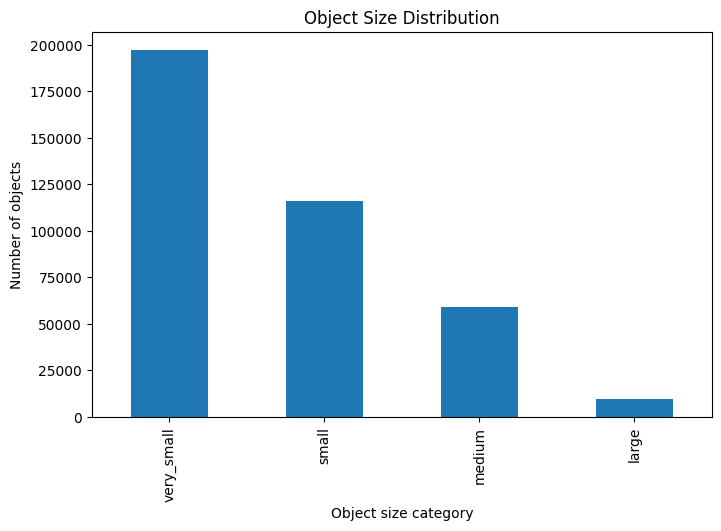

In [49]:
size_counts = (
    df["size_category"]
    .value_counts()
)

plt.figure(figsize=(8, 5))

size_counts.plot(
    kind="bar"
)

plt.title(
    "Object Size Distribution"
)

plt.xlabel(
    "Object size category"
)

plt.ylabel(
    "Number of objects"
)

plt.show()

In [50]:
#Graphe — Largeur / hauteur

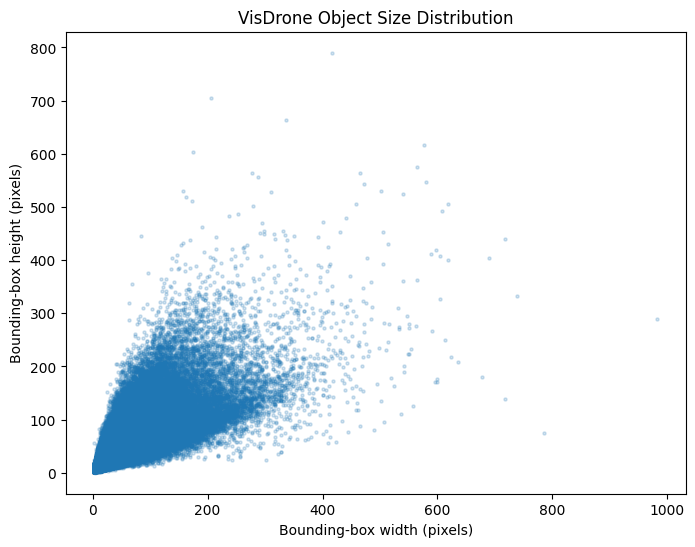

In [51]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["width"],
    df["height"],
    alpha=0.2,
    s=5
)

plt.xlabel(
    "Bounding-box width (pixels)"
)x

plt.ylabel(
    "Bounding-box height (pixels)"
)

plt.title(
    "VisDrone Object Size Distribution"
)

plt.show()

In [52]:
#Analyse de l'oclusion

In [53]:
occlusion_counts = (
    df["occlusion"]
    .value_counts()
    .sort_index()
)

occlusion_counts

occlusion
0    184114
1    161112
2     36738
Name: count, dtype: int64

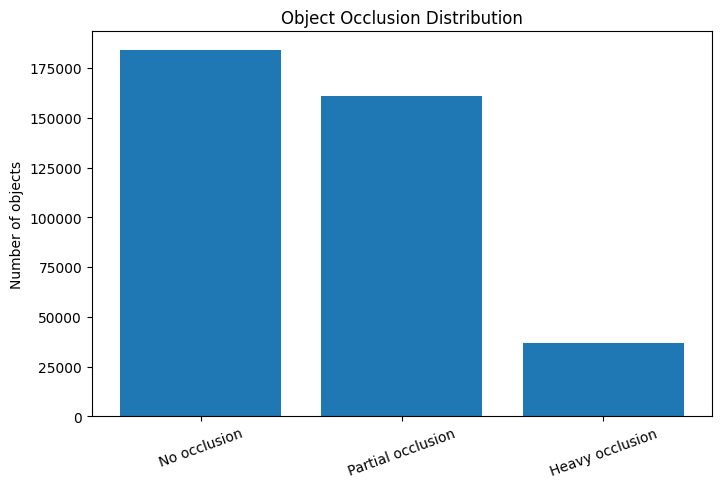

In [54]:
#Graphe - Oclusion
labels = [
    "No occlusion",
    "Partial occlusion",
    "Heavy occlusion"
]

values = [
    occlusion_counts.get(
        0, 0
    ),
    occlusion_counts.get(
        1, 0
    ),
    occlusion_counts.get(
        2, 0
    )
]

plt.figure(figsize=(8, 5))

plt.bar(
    labels,
    values
)

plt.title(
    "Object Occlusion Distribution"
)

plt.ylabel(
    "Number of objects"
)

plt.xticks(
    rotation=20
)

plt.show()

In [55]:
#Troncature analyse
truncation_counts = (
    df["truncation"]
    .value_counts()
    .sort_index()
)

truncation_counts

truncation
0    367119
1     14845
Name: count, dtype: int64

In [56]:
#Graphe — Troncature

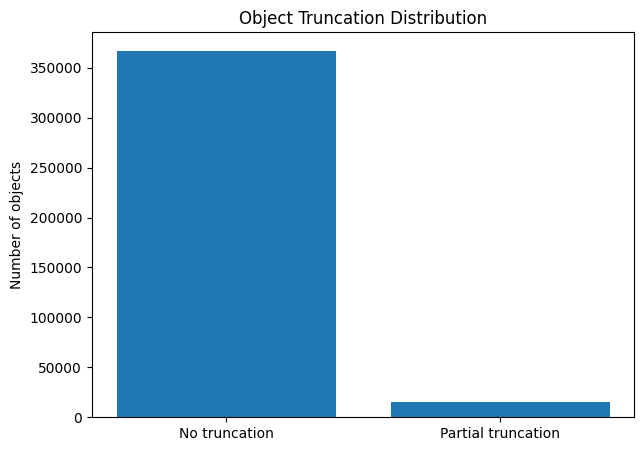

In [57]:
labels = [
    "No truncation",
    "Partial truncation"
]

values = [
    truncation_counts.get(
        0, 0
    ),
    truncation_counts.get(
        1, 0
    )
]

plt.figure(figsize=(7, 5))

plt.bar(
    labels,
    values
)

plt.title(
    "Object Truncation Distribution"
)

plt.ylabel(
    "Number of objects"
)

plt.show()

In [58]:
#Object spatial heatmap
x_center = (
    df["x"] +
    df["width"] / 2
) / df["image_width"]

y_center = (
    df["y"] +
    df["height"] / 2
) / df["image_height"]

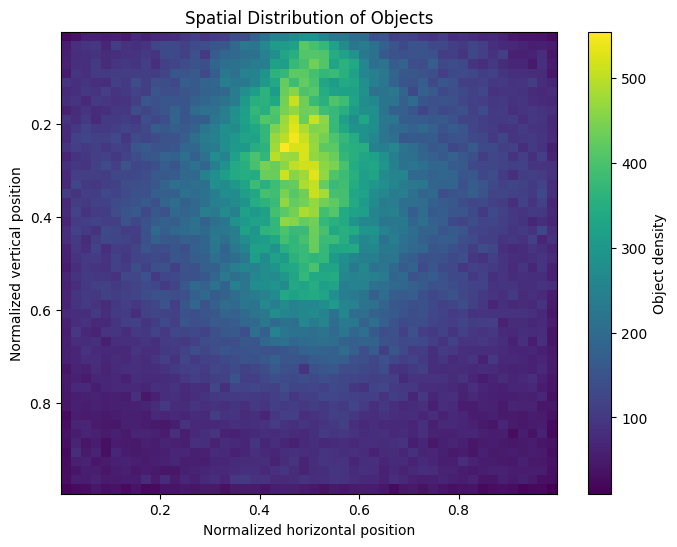

In [59]:
plt.figure(figsize=(8, 6))

plt.hist2d(
    x_center,
    y_center,
    bins=50
)

plt.colorbar(
    label="Object density"
)

plt.gca().invert_yaxis()

plt.xlabel(
    "Normalized horizontal position"
)

plt.ylabel(
    "Normalized vertical position"
)

plt.title(
    "Spatial Distribution of Objects"
)

plt.show()

In [60]:
# result exportation
df.to_csv(
    "VisDrone_DET_annotations_analysis.csv",
    index=False
)

summary_df.to_csv(
    "VisDrone_DET_split_summary.csv",
    index=False
)

objects_per_image.to_csv(
    "VisDrone_DET_objects_per_image.csv",
    index=False
)

In [61]:
#JSON Resume exportation
dataset_summary = {

    "dataset":
        "VisDrone-DET",

    "splits":
        summary_df.to_dict(
            orient="records"
        ),

    "total_images":
        int(len(images_df)),

    "total_objects":
        int(len(df)),

    "num_classes":
        int(df["category"].nunique()),

    "class_distribution":
        class_counts.to_dict(),

    "mean_objects_per_image":
        float(
            objects_per_image[
                "object_count"
            ].mean()
        ),

    "mean_bbox_width":
        float(
            df["width"].mean()
        ),

    "mean_bbox_height":
        float(
            df["height"].mean()
        ),

    "mean_relative_area":
        float(
            df["relative_area"].mean()
        ),

    "occlusion_distribution":
        occlusion_counts.to_dict(),

    "truncation_distribution":
        truncation_counts.to_dict()
}

In [62]:
import json

with open(
    "VisDrone_DET_dataset_summary.json",
    "w"
) as f:

    json.dump(
        dataset_summary,
        f,
        indent=4
    )